In [ ]:
import torch 
import torch.nn as nn
from torchdiffeq import odeint 
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

### Example 0: fitting an NODE to model the dynamics of stock price data and forecast future prices (obviously terrible fit because one is deterministic while the other is stochastic in nature)
#### In this case we need to resort to latent NODEs (if not NSDEs): where we model some latent state instead of the raw price. The architecture is as follows: 
#### 1. Encoder: standard RNN (GRU or LSTM) that processes noisy input at discrete times and compresses it into a clean, deterministic initial condition  
#### 2. ODE solver: evolves and integrate the initial latent state $h(t_0)$ forward, using an NN to define the continuous-time dynamics of $h$  
#### 3. Decoder: a final network that takes the smooth $h(t)$ and decodes it into a prediction of the observed noisy price $y(t)$
##### An ideal financial data type in this case would be irregularly sampled high-frequency trading data or macroeconomic factors 

In [69]:
# Download and preprocess data from yfinance
def get_data(ticker="AAPL", start="2022-01-01", end="2025-01-01"):
    data = yf.download(ticker, start=start, end=end)
    print(data.head())
    prices = data['Close'].values.flatten()

    if len(prices) == 0:
        print("Error: No data retrieved!")
        return None, None
    log_returns = np.diff(np.log(prices))

    if len(log_returns) < 1:
        print("Error: Not enough data for log-returns")
        return None, None
    

    log_returns = (log_returns - np.mean(log_returns)) / np.std(log_returns)
    t = np.linspace(0, len(log_returns) - 1, len(log_returns))
    return torch.tensor(t, dtype=torch.float32), torch.tensor(log_returns, dtype=torch.float32).unsqueeze(1)
 
t, y = get_data("AAPL")
if t is None or y is None:
    print("Error loading data!")
else:
    print("Data loaded successfully. Shape: t =", t.shape, "y =", y.shape)


C:\Users\pengl\AppData\Local\Temp\ipykernel_24468\3851559476.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start, end=end)
[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker            AAPL        AAPL        AAPL        AAPL       AAPL
Date                                                                 
2022-01-03  178.443100  179.296061  174.227380  174.345024  104487900
2022-01-04  176.178406  179.354917  175.609770  179.050994   99310400
2022-01-05  171.492065  176.639180  171.217554  176.090157   94537600
2022-01-06  168.629318  171.864651  168.276373  169.315597   96904000
2022-01-07  168.795975  170.727370  167.678316  169.501866   86709100
Data loaded successfully. Shape: t = torch.Size([752]) y = torch.Size([752, 1])


In [70]:
# Define an NODE model
class ODEFunc(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, 1)   
        )
    
    def forward(self, t, y):
        return self.net(y)
        

In [72]:
# Training loop
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
func = ODEFunc().to(device)

optimizer = torch.optim.Adam(func.parameters(), lr=0.0001) # high learning rate causes dynamics of ODE
                                                            # to become unstable / stiff during training
loss_fn = nn.MSELoss()

# Initial condition 
y0 = y[0].to(device)
t_span = t.to(device)
y_data = y.to(device)

for epoch in range(1000):
    optimizer.zero_grad()

    # Predict using the ODE solver
    y_pred = odeint(func, y0, t_span)

    print(f"Epoch {epoch}, y_pred shape: {y_pred.shape}")

    # Compute loss and backprop
    loss = loss_fn(y_pred, y_data)
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

Epoch 0, y_pred shape: torch.Size([752, 1])
Epoch 0, Loss: 18319.5273
Epoch 1, y_pred shape: torch.Size([752, 1])
Epoch 2, y_pred shape: torch.Size([752, 1])
Epoch 3, y_pred shape: torch.Size([752, 1])
Epoch 4, y_pred shape: torch.Size([752, 1])
Epoch 5, y_pred shape: torch.Size([752, 1])
Epoch 6, y_pred shape: torch.Size([752, 1])
Epoch 7, y_pred shape: torch.Size([752, 1])
Epoch 8, y_pred shape: torch.Size([752, 1])
Epoch 9, y_pred shape: torch.Size([752, 1])
Epoch 10, y_pred shape: torch.Size([752, 1])
Epoch 11, y_pred shape: torch.Size([752, 1])
Epoch 12, y_pred shape: torch.Size([752, 1])
Epoch 13, y_pred shape: torch.Size([752, 1])
Epoch 14, y_pred shape: torch.Size([752, 1])
Epoch 15, y_pred shape: torch.Size([752, 1])
Epoch 16, y_pred shape: torch.Size([752, 1])
Epoch 17, y_pred shape: torch.Size([752, 1])
Epoch 18, y_pred shape: torch.Size([752, 1])
Epoch 19, y_pred shape: torch.Size([752, 1])
Epoch 20, y_pred shape: torch.Size([752, 1])
Epoch 21, y_pred shape: torch.Size([752

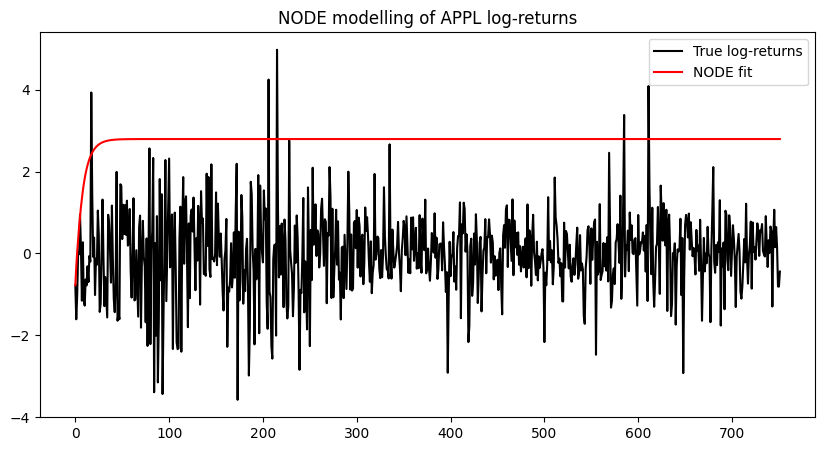

In [73]:
# Plotting and evaluation
y_pred = odeint(func, y0, t_span).detach().cpu().squeeze()

plt.figure(figsize=(10,5))
plt.plot(t, y, label="True log-returns", color='black')
plt.plot(t, y_pred, label="NODE fit", color='red')
plt.legend()
plt.title("NODE modelling of APPL log-returns")
plt.show()

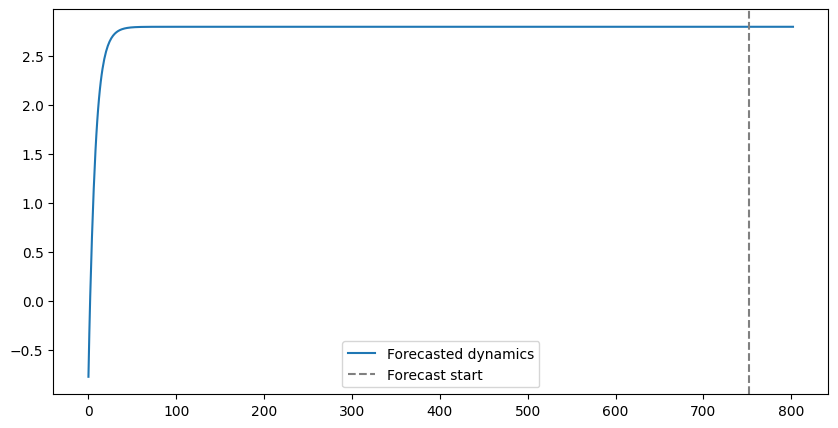

In [74]:
 # Forecasting using our NODE model
with torch.no_grad():
    t_future = torch.linspace(0, len(t)+50, len(t)+50).to(device)
    y_future = odeint(func, y0, t_future).cpu().squeeze()

plt.figure(figsize=(10,5))
plt.plot(t_future, y_future, label="Forecasted dynamics")
plt.axvline(x=len(t), color='grey', linestyle='--', label='Forecast start')
plt.legend()
plt.show()